In [4]:
import numpy as np
import matplotlib.pyplot as plt
class SigmoidNeuron:
    def __init__(self, num_inputs, learning_rate = 0.5):
        self.weight = np.random.randn(num_inputs) * 0.1
        self.bias = 0.0
        self.learning_rate = learning_rate

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def predict(self, x):
        z = np.dot(self.weight, x) + self.bias
        return self.sigmoid(z)

    def sigmoid_derivative(self, z):
        s = self.sigmoid(z)
        return s * (1 - s)

    def train(self,training_inputs, labels, epochs = 2000):
        for epoch in range(epochs):
            total_loss = 0
            for x,y in zip(training_inputs, labels):
                x = np.array(x)
                z = np.dot(self.weight, x) + self.bias
                a = self.sigmoid(z)
                error = a- y
                gradient = error * self.sigmoid_derivative(z)

                self.weight -= self.learning_rate * gradient * x
                self.bias -= self.learning_rate * gradient
                total_loss += 0.5 * (error ** 2)

inputs = [(0, 0), (0, 1), (1, 0), (1, 1)]
labels = [1, 1, 1, 0]  

n = SigmoidNeuron(num_inputs = 2)
n.train(inputs, labels, epochs = 2000)

for x, y in zip(inputs, labels):
    raw = n.predict(np.array(x))
    thresholded = 1 if raw > 0.5 else 0
    print(f"{x[0]:>3} {x[1]:>3} | {raw:>10.4f} | {thresholded:>11} | {y}")

  0   0 |     0.9998 |           1 | 1
  0   1 |     0.9446 |           1 | 1
  1   0 |     0.9445 |           1 | 1
  1   1 |     0.0656 |           0 | 0


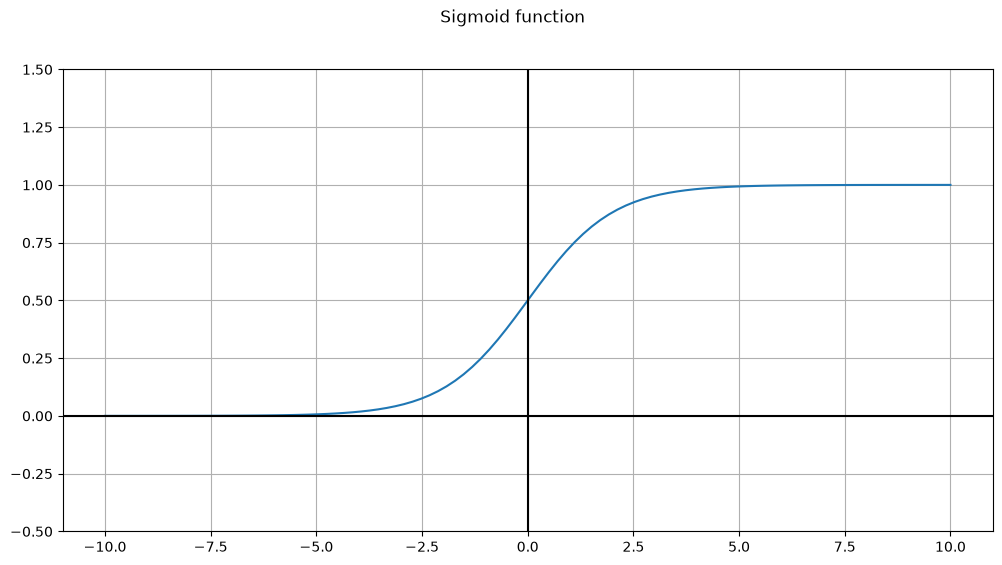

In [5]:
# Plot the sigmoid function
def sigmoid(x):
    return 1.0/ (1.0 + np.exp(-x))
vals = np.linspace(-10, 10, num=100, dtype=np.float32)
activation = sigmoid(vals)
fig = plt.figure(figsize=(12,6))
fig.suptitle('Sigmoid function')
plt.plot(vals, activation)
plt.grid(True, which='both')
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.yticks()
plt.ylim([-0.5, 1.5]);

## Logic Gates

In [6]:
def logic_gate(w1, w2, b):
    return lambda x1, x2: sigmoid(w1 * x1 + w2 * x2 + b)

def test(gate):
    for a, b in (0, 0), (0, 1), (1, 0), (1, 1):
        print("{}, {}: {}".format(a, b, np.round(gate(a, b))))

In [7]:
# OR GATE
or_gate = logic_gate(20,20,-10)
test(or_gate)

0, 0: 0.0
0, 1: 1.0
1, 0: 1.0
1, 1: 1.0


In [10]:
# AND GATE
and_gate = logic_gate(11, 10, -20)
test(and_gate)

0, 0: 0.0
0, 1: 0.0
1, 0: 0.0
1, 1: 1.0


In [11]:
# NOR GATE
nor_gate = logic_gate(-20, -20, 10)
test(nor_gate)

0, 0: 1.0
0, 1: 0.0
1, 0: 0.0
1, 1: 0.0


In [12]:
#NAND GATE
nand_gate = logic_gate(-11, -10, 20)
test(nand_gate)

0, 0: 1.0
0, 1: 1.0
1, 0: 1.0
1, 1: 0.0


In [13]:
#XOR GATE
def xor_gate(a, b):
    c = or_gate(a,b)
    d = nand_gate(a,b)
    return and_gate(c,d)
test(xor_gate)

0, 0: 0.0
0, 1: 1.0
1, 0: 1.0
1, 1: 0.0


In [14]:
## Function for softmax for vector and matrix
def soft_max_vec(vec):
    return np.exp(vec)/(np.sum(np.exp(vec)))

def soft_max_mat(mat):
    return np.exp(mat)/(np.sum(np.exp(mat),axis=1).reshape(-1,1))